In [1]:
import pandas as pd
import numpy as np


pd.set_option('display.max_columns', None)
# pd.set_option('display.max_rows', None)
df_telco = pd.read_csv('telco_v2.csv')

In [2]:
CHURN_COLOR = '#ff5517'
NO_CHURN_COLOR = '#4895a1'

YES_COLOR = '#4c72b0'
NO_COLOR = '#aab0b7'

In [3]:
df_telco.shape

(7043, 48)

In [4]:
df_telco.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 48 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   str    
 1   Gender                             7043 non-null   str    
 2   Age                                7003 non-null   float64
 3   Married                            7043 non-null   str    
 4   Dependents                         7043 non-null   str    
 5   Number of Dependents               7009 non-null   float64
 6   Country                            7043 non-null   str    
 7   State                              7043 non-null   str    
 8   City                               7043 non-null   str    
 9   Zip Code                           7018 non-null   float64
 10  Latitude                           7008 non-null   float64
 11  Longitude                          7007 non-null   float64
 12  Pop

In [5]:
df_telco.columns = df_telco.columns.str.lower().str.replace(' ', '_')

In [6]:
df_telco['customer_id'].nunique()

7043

In [7]:
df_telco.head()

,customer_id,gender,age,married,dependents,number_of_dependents,country,state,city,zip_code,latitude,longitude,population,quarter,referred_a_friend,number_of_referrals,tenure_in_months,offer,phone_service,avg_monthly_long_distance_charges,multiple_lines,internet_type,avg_monthly_gb_download,online_security,online_backup,device_protection_plan,premium_tech_support,streaming_tv,streaming_movies,streaming_music,avg_monthly_gb_streaming_movies,avg_monthly_gb_streaming_music,avg_monthly_gb_streaming_tv,unlimited_data,contract,paperless_billing,payment_method,monthly_charge,total_charges,total_refunds,total_extra_data_charges,total_long_distance_charges,total_revenue,customer_status,churn_label,churn_score,churn_category,churn_reason
0,8779-QRDMV,Male,78.0,No,no,0.0,United States,California,los angeles,90022.0,34.023810,-118.156582,68701.0,Q3,No,0.0,1.0,NaN,NO,0.00,No,DSL,8.0,No,No,Yes,No,no,Yes,no,0,2,0,NO,Month-to-Month,yes,Bank Withdrawal,39.65,39.65,0.00,20.0,0.00,59.65,churned,yes,91.0,Competitor,Competitor offered more data
1,7495-OOKFY,female,74.0,yes,yes,1.0,UNITED STATES,California,Los Angeles,90063.0,34.044271,-118.185237,55668.0,Q3,YES,1.0,8.0,Offer E,Yes,48.85,yes,fiber optic,17.0,NO,YES,NO,no,NO,No,No,0,0,0,Yes,Month-to-Month,yes,credit card,80.65,633.30,0.00,0.0,390.80,1024.10,Churned,Yes,69.0,Competitor,Competitor made better offer
2,1658-bygoy,male,71.0,NO,yes,3.0,United States,california,Los Angeles,90065.0,34.108833,-118.229715,47534.0,Q3,No,0.0,18.0,Offer D,Yes,11.33,Yes,FIBER OPTIC,52.0,No,No,No,No,yes,Yes,Yes,0,0,2,Yes,Month-to-Month,Yes,bank withdrawal,95.45,8739.55,45.61,0.0,203.94,1910.88,Churned,Yes,81.0,Competitor,Competitor made better offer
3,4598-XLKNJ,Female,78.0,yes,Yes,1.0,UNITED STATES,California,Inglewood,90303.0,33.936291,-118.332639,27778.0,Q3,Yes,1.0,25.0,offer c,Yes,19.76,No,Fiber Optic,12.0,No,Yes,Yes,No,Yes,Yes,No,2,0,0,Yes,Month-to-Month,Yes,Bank Withdrawal,98.50,2514.50,13.43,0.0,494.00,2995.07,Churned,yes,88.0,Dissatisfaction,Limited range of services
4,4846-WHAFZ,Female,80.0,YES,YES,1.0,United States,California,WHITTIER,NaN,33.972119,-118.020188,26265.0,q3,YES,1.0,37.0,Offer C,Yes,6.33,Yes,Fiber Optic,14.0,no,No,NO,No,no,no,No,0,0,0,YES,Month-to-Month,yes,BANK WITHDRAWAL,76.50,2868.15,0.00,0.0,234.21,3102.36,Churned,Yes,67.0,Price,Extra data charges


In [8]:
df_telco.describe(include='float64')

,age,number_of_dependents,zip_code,latitude,longitude,population,number_of_referrals,tenure_in_months,avg_monthly_long_distance_charges,avg_monthly_gb_download,monthly_charge,total_charges,total_refunds,total_extra_data_charges,total_long_distance_charges,total_revenue,churn_score
count,7003.000000,7009.000000,7018.000000,7008.000000,7007.000000,7011.000000,7006.000000,7011.000000,7009.000000,7010.000000,7005.000000,7013.000000,7010.000000,7009.000000,7008.000000,7014.000000,7014.000000
mean,93.329716,58.220859,93536.683528,71.956739,-62.458888,22163.282556,45.994148,83.940807,72.133845,73.013980,113.265496,2335.464536,58.971673,48.008275,789.642837,3089.030676,103.265469
std,543.182471,601.575489,1951.109064,476.081068,640.277834,21154.150823,519.690378,590.009467,562.238515,583.751484,572.427272,2356.205392,605.528820,498.990015,974.146779,2916.963485,541.456957
min,19.000000,0.000000,90001.000000,32.555828,-124.301372,11.000000,0.000000,1.000000,0.000000,0.000000,18.250000,18.800000,0.000000,0.000000,0.000000,21.360000,5.000000
25%,32.000000,0.000000,92108.000000,33.993991,-121.777179,2349.000000,0.000000,9.000000,9.330000,4.000000,35.800000,407.050000,0.000000,0.000000,72.607500,619.702500,41.000000
50%,46.000000,0.000000,93531.000000,36.296851,-119.486225,17494.000000,0.000000,29.000000,23.180000,17.000000,70.550000,1412.650000,0.000000,0.000000,413.370000,2160.355000,62.000000
75%,60.000000,0.000000,95345.000000,38.224869,-117.931698,36137.000000,3.000000,56.000000,36.710000,27.000000,90.250000,3856.750000,0.000000,0.000000,1228.132500,4887.487500,76.000000
max,9905.000000,9550.000000,105423.000000,9848.893250,9874.797063,105285.000000,9943.000000,9915.000000,9692.350000,9634.000000,10001.800000,16652.150000,9995.000000,9831.000000,10635.400000,18605.550000,9991.000000


Age tem maximo de 9K anos heheh, tambem nao acho que alguem pode ter 9K dependentes, ao menos 'e possivel confirmar parcilamente a informacao com o bool de dependentes.Tambem pouco provavel que alguem tenha indicado 9K pessoas. Aparentemente o dataset tem bastante outlier nas variaveis de float64.. Vou considerar para Age a idade da pessoa mais velha ja registrada, 122 anos, vou deixar nan

### Cenario atual/Motivos do churn

As colunas `churn_category` e `churn_reason` só existem para quem saiu (1.869 clientes). A **concorrência** domina: **Competitor** responde por 841 (~45%) dos churners. Em seguida vêm experiência/atendimento (**Attitude** 314 + **Dissatisfaction** 303 ≈ 33% juntos), **Price** 211 e **Other** 200.

In [9]:
# normaliza customer_status: caixa mista (Stayed/stayed/STAYED, Churned/..., Joined/...)
df_telco['customer_status'] = df_telco['customer_status'].str.lower()

df_telco['customer_status'].value_counts()

customer_status
stayed     4720
churned    1869
joined      454
Name: count, dtype: int64

In [10]:
import plotly.graph_objects as go

cat = df_telco['churn_category'].dropna().value_counts().sort_values()

fig = go.Figure(go.Bar(
    x=cat.values,
    y=cat.index,
    orientation='h',
    marker_color=CHURN_COLOR,
    text=cat.values,
    textposition='outside',
))
fig.update_layout(
    title=dict(text='Churn por categoria de motivo', x=0, font=dict(size=16)),
    xaxis_title='Clientes',
    yaxis_title=None,
    plot_bgcolor='white',
    margin=dict(l=10, r=60, t=50, b=10),
    height=400,
)
fig.show()

In [11]:
import plotly.graph_objects as go

reason = df_telco['churn_reason'].dropna().value_counts().sort_values()

fig = go.Figure(go.Bar(
    x=reason.values,
    y=reason.index,
    orientation='h',
    marker_color=CHURN_COLOR,
    text=reason.values,
    textposition='outside',
))
fig.update_layout(
    title=dict(text='Churn por motivo detalhado', x=0, font=dict(size=16)),
    xaxis_title='Clientes',
    yaxis_title=None,
    plot_bgcolor='white',
    margin=dict(l=10, r=70, t=50, b=10),
    height=620,
)
fig.show()

## Tratamentos e criação de features

In [12]:
to_str = ['customer_id', 'zip_code', 'latitude', 'longitude']

demographics_bool = ['married', 'dependents', 'referred_a_friend', 'paperless_billing']

services_bool = [
    'phone_service',
    'multiple_lines',
    'online_security',
    'online_backup',
    'device_protection_plan',
    'premium_tech_support',
    'streaming_tv',
    'streaming_movies',
    'streaming_music',
    'unlimited_data',
]

to_bool = demographics_bool + services_bool

categorical_cols = ['internet_type', 'contract', 'payment_method', 'offer']

streaming_gb_cols = ['avg_monthly_gb_streaming_movies', 'avg_monthly_gb_streaming_music', 'avg_monthly_gb_streaming_tv']

qcut_cols = [
    'avg_monthly_long_distance_charges',
    'tenure_in_months',
    'avg_monthly_gb_download',
    'monthly_charge',
    'total_charges',
]

binary_cols = ['total_refunds', 'total_extra_data_charges']

to_remove_later = ['customer_status', 'churn_label', 'churn_score', 'churn_category', 'churn_reason']

### Breve limpeza dos dados 

In [13]:
df_telco[to_str] = df_telco[to_str].astype('str')
df_telco[to_bool] = df_telco[to_bool].apply(lambda s: s.str.lower().eq('yes'))
df_telco[categorical_cols] = df_telco[categorical_cols].apply(lambda s: s.str.lower())

df_telco['churn_label'] = df_telco['churn_label'].str.lower().eq('yes')

df_telco['internet_type'] = df_telco['internet_type'].replace('none', np.nan)
df_telco['offer'] = df_telco['offer'].fillna('none')  # missing = none = sem oferta

df_telco['has_internet'] = df_telco['internet_type'].notna()
df_telco['num_services'] = df_telco[services_bool].astype(int).sum(axis=1) + df_telco['has_internet'].astype(int)

df_telco['customer_type'] = np.select(
    [
        df_telco['has_internet'] & df_telco['phone_service'],
        df_telco['has_internet'] & ~df_telco['phone_service'],
        ~df_telco['has_internet'] & df_telco['phone_service'],
    ],
    ['both', 'internet_only', 'phone_only'],
    default='none',
)

for col in streaming_gb_cols:
    df_telco[col] = df_telco[col].astype('int').astype('category')

for col in qcut_cols:
    bins = pd.qcut(df_telco[col], q=4, duplicates='drop')
    labels = [f'{iv.left:.0f}-{iv.right:.0f}' for iv in bins.cat.categories]
    df_telco[col + '_bin'] = bins.cat.rename_categories(labels)

In [14]:
df_telco[df_telco['age'] > 122].shape

(69, 56)

In [15]:
df_telco.loc[df_telco['age'] > 100, 'age'] = np.nan

In [16]:
df_telco.loc[(df_telco['number_of_dependents'] >= 1) & (df_telco['dependents'] == 'No')]
#Ao menos nao tem inconsistencia. Acho que nao vou considerar essa coluna para modelagem, vou usar so a bool

,customer_id,gender,age,married,dependents,number_of_dependents,country,state,city,zip_code,latitude,longitude,population,quarter,referred_a_friend,number_of_referrals,tenure_in_months,offer,phone_service,avg_monthly_long_distance_charges,multiple_lines,internet_type,avg_monthly_gb_download,online_security,online_backup,device_protection_plan,premium_tech_support,streaming_tv,streaming_movies,streaming_music,avg_monthly_gb_streaming_movies,avg_monthly_gb_streaming_music,avg_monthly_gb_streaming_tv,unlimited_data,contract,paperless_billing,payment_method,monthly_charge,total_charges,total_refunds,total_extra_data_charges,total_long_distance_charges,total_revenue,customer_status,churn_label,churn_score,churn_category,churn_reason,has_internet,num_services,customer_type,avg_monthly_long_distance_charges_bin,tenure_in_months_bin,avg_monthly_gb_download_bin,monthly_charge_bin,total_charges_bin


In [17]:
df_telco['internet_type'].value_counts(normalize=True)

internet_type
fiber optic    0.550118
dsl            0.299438
cable          0.150444
Name: proportion, dtype: float64

In [18]:
df_telco['internet_type'].isna().sum()

np.int64(1526)

In [19]:
# 'none' já foi convertido para NaN na célula de transformação
df_telco['internet_type'].isna().sum()

np.int64(1526)

In [20]:
df_telco.loc[(df_telco['phone_service'] == True) & (df_telco['internet_type'].isna())].shape
#Beleza, isso confirma que nao tem inconsistencia, se a pessoa n tem internet esta como none tambem 'e nan, pq ela s'o tem servico de celular

(1526, 56)

In [21]:
df_telco['quarter'].value_counts(normalize=True)#Oxi, ai complicou s'o tem Q3

quarter
Q3    0.802073
q3    0.197927
Name: proportion, dtype: float64

In [22]:
df_telco['churn_label'].value_counts(normalize=True)

churn_label
False    0.73463
True     0.26537
Name: proportion, dtype: float64

In [23]:
df_telco['city'] = df_telco['city'].str.lower().str.strip()

In [24]:
df_telco[['churn_label','contract']].value_counts(normalize=True)
#Eu nao sei se essa base foi retirada de forma que esse cenario realmente representa a realidade,
#me parece obvio que a maior probabilidade seja do cliente mes a mes. Nao to querendo usar essa feature

churn_label  contract      
False        month-to-month    0.277581
             two year          0.260542
True         month-to-month    0.234985
False        one year          0.196507
True         one year          0.023570
             two year          0.006815
Name: proportion, dtype: float64

### Missing values

<Axes: >

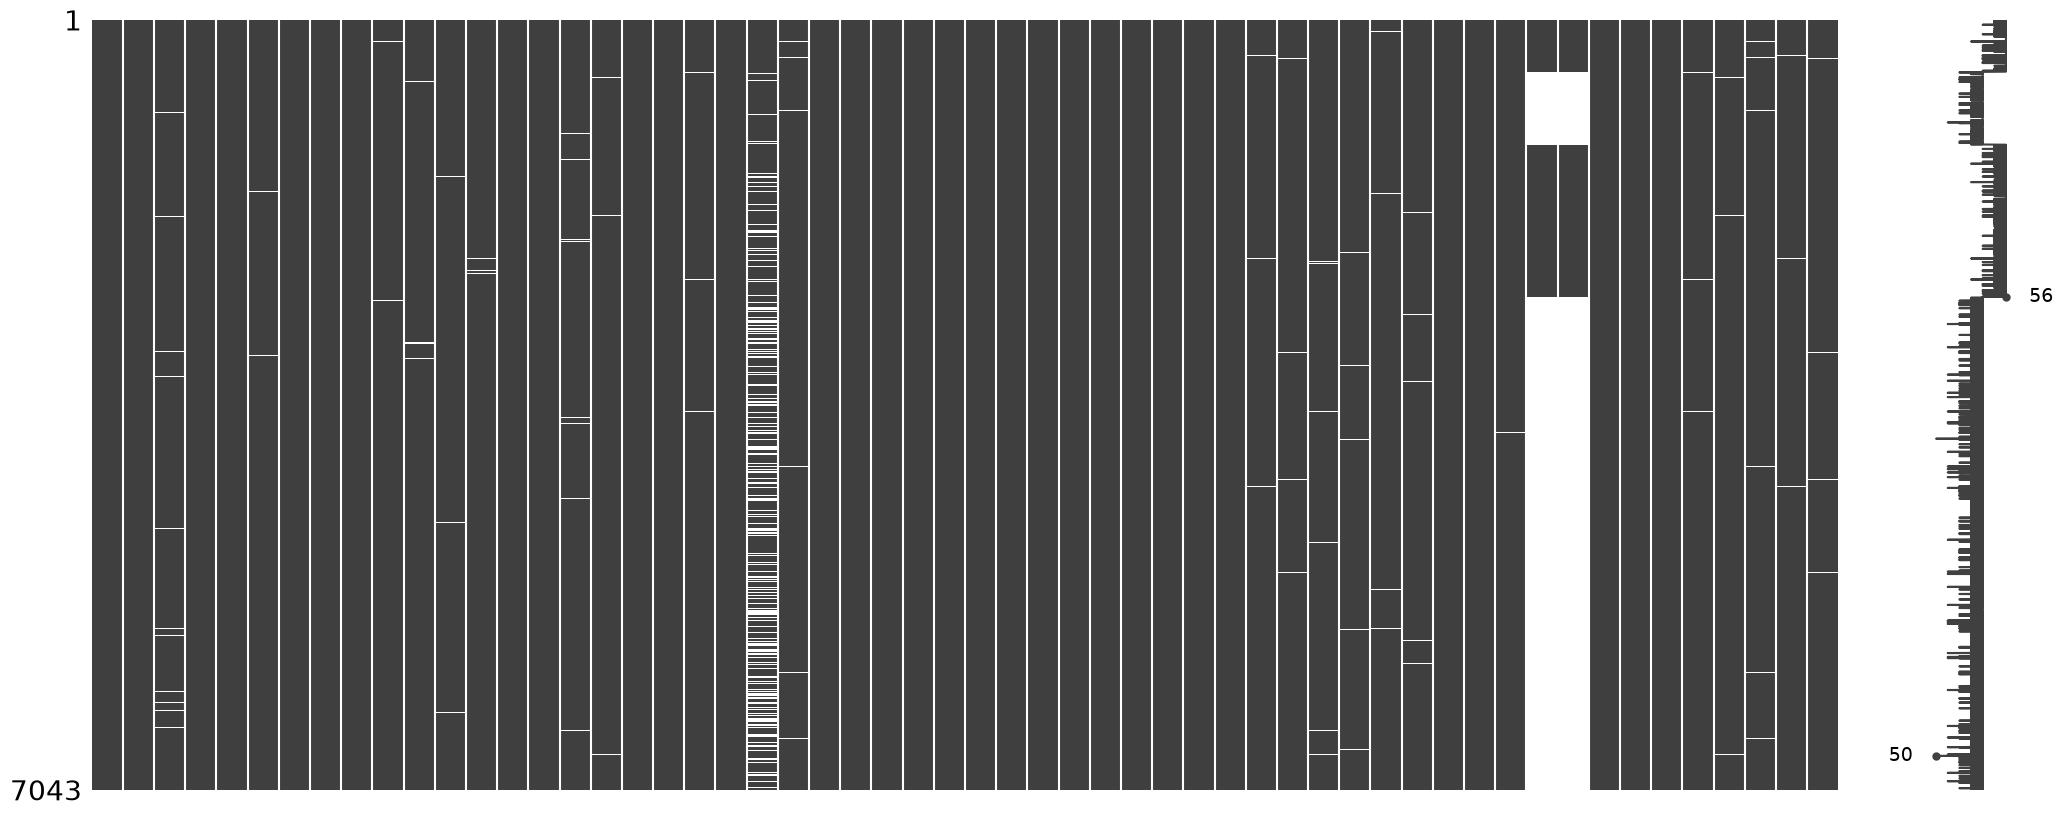

In [25]:
import missingno as msno

msno.matrix(df_telco)

Quantidade de missing values concentrada apenas nas colunas: offer e internet type, que nāo acho que vai ser um problema.

In [26]:
churn = df_telco['churn_label']

def churn_rate_by_bool(cols):
    return pd.DataFrame([
        {
            'variavel': col,
            'valor': valor,
            'qtd_usuarios': int(mask.sum()),
            'churn_pct': round(churn[mask].mean() * 100, 2),
        }
        for col in cols
        for valor, mask in [(True, df_telco[col]), (False, ~df_telco[col])]
    ])

churn_by_service = churn_rate_by_bool(services_bool)
churn_by_service

,variavel,valor,qtd_usuarios,churn_pct
0,phone_service,True,6361,26.71
1,phone_service,False,682,24.93
2,multiple_lines,True,2971,28.61
3,multiple_lines,False,4072,25.02
4,online_security,True,2019,14.61
5,online_security,False,5024,31.33
6,online_backup,True,2429,21.53
7,online_backup,False,4614,29.17
8,device_protection_plan,True,2422,22.50
9,device_protection_plan,False,4621,28.65


In [27]:
import plotly.graph_objects as go
import nbformat
import plotly.io._renderers as _renderers

_renderers.nbformat = nbformat  # nbformat foi instalado depois do kernel iniciar

churn_pivot = churn_by_service.pivot(index='variavel', columns='valor', values='churn_pct')
churn_pivot = churn_pivot.rename(columns={True: 'yes', False: 'no'})
churn_pivot['gap'] = churn_pivot['no'] - churn_pivot['yes']
churn_pivot = churn_pivot.sort_values('gap', ascending=True)

labels = churn_pivot.index.str.replace('_', ' ').str.title()

fig = go.Figure()

fig.add_trace(go.Bar(
    y=labels,
    x=churn_pivot['yes'],
    name='Sim (tem serviço)',
    orientation='h',
    marker_color=YES_COLOR,
    text=churn_pivot['yes'].round(0).astype(int).astype(str) + '%',
    textposition='outside',
))

fig.add_trace(go.Bar(
    y=labels,
    x=churn_pivot['no'],
    name='Não (não tem serviço)',
    orientation='h',
    marker_color=NO_COLOR,
    text=churn_pivot['no'].round(0).astype(int).astype(str) + '%',
    textposition='outside',
))

fig.update_layout(
    title=dict(text='Churn por serviços', x=0, font=dict(size=18)),
    xaxis_title='% de churn',
    barmode='group',
    height=520,
    margin=dict(l=10, r=10, t=50, b=10),
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1),
    plot_bgcolor='white',
)

fig.show()

Online security: 15% de churn em clientes que tem o servico vs 31% em clientes que nao tem
Onlien Backup e Device Protection Plan: 22% vs 29% em clientes que nao tem
Phone Service e multiple lines: 25% vs 27%/29% em clientes que nao tem
Streaming  Moveis e Streaming TV: 24% vs 30% em clientes que nao tem

Vale entender as diferencas, verificar se clientes com  mais produtos tiveram menos churn


### Serviços contratados (bool)

| Serviço | Com serviço | Sem serviço | Δ (p.p.) | Leitura |
|---|---:|---:|---:|---|
| Online Security | 14,6% | 31,3% | +16,7 | sem o serviço churn **2,1×** maior |
| Premium Tech Support | 15,2% | 31,2% | +16,0 | sem o serviço churn **2,1×** maior |
| Online Backup | 21,5% | 29,2% | +7,6 | sem o serviço churn **1,4×** maior |
| Device Protection Plan | 22,5% | 28,7% | +6,1 | sem o serviço churn **1,3×** maior |
| Streaming TV | 30,1% | 24,3% | −5,7 | **com** o serviço churn **1,2×** maior |
| Streaming Movies | 29,9% | 24,4% | −5,6 | **com** o serviço churn **1,2×** maior |
| Streaming Music | 29,3% | 25,0% | −4,2 | **com** o serviço churn **1,2×** maior |
| Multiple Lines | 28,6% | 25,0% | −3,6 | **com** o serviço churn **1,1×** maior |
| Unlimited Data | 31,7% | 16,0% | −15,7 | **com** o serviço churn **2,0×** maior |
| Phone Service | 26,7% | 24,9% | −1,8 | praticamente igual |

In [28]:
churn_by_demographics = churn_rate_by_bool(demographics_bool)

churn_pivot = churn_by_demographics.pivot(index='variavel', columns='valor', values='churn_pct')
churn_pivot = churn_pivot.rename(columns={True: 'yes', False: 'no'})
churn_pivot['gap'] = churn_pivot['no'] - churn_pivot['yes']
churn_pivot = churn_pivot.sort_values('gap', ascending=True)

labels = churn_pivot.index.str.replace('_', ' ').str.title()

fig = go.Figure()

fig.add_trace(go.Bar(
    y=labels,
    x=churn_pivot['yes'],
    name='Sim',
    orientation='h',
    marker_color=YES_COLOR,
    text=churn_pivot['yes'].round(0).astype(int).astype(str) + '%',
    textposition='outside',
))

fig.add_trace(go.Bar(
    y=labels,
    x=churn_pivot['no'],
    name='Não',
    orientation='h',
    marker_color=NO_COLOR,
    text=churn_pivot['no'].round(0).astype(int).astype(str) + '%',
    textposition='outside',
))

fig.update_layout(
    title=dict(text='Churn por variáveis demográficas', x=0, font=dict(size=18)),
    xaxis_title='% de churn',
    barmode='group',
    height=400,
    margin=dict(l=10, r=10, t=50, b=10),
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1),
    plot_bgcolor='white',
)

fig.show()

33% dos que nao possuem dependente realizam churn vs 7% dos que tem dependentes... Na minha cabeca isso pode fazer sentido, pq a escolha de fazer o churn passaria por mais pessoas, so uma hipotese. 
33% dos que nao fizeram uma indicacao realizam churn vs 19% dos que fizeram. Pode fazer sentido que haja algo aqui levando em conta que se a pessoa indica 'e por que esta bem satisfeita com o servico. 
Aqui algo interessante: 16% dos que nao aceitaram fatura em papel vs 34% dos que aceitaram. Na verdade, a interpretacao nem ta certa, o default provavlemente 'e conta em papel, e depois vc tem que ir e solicitar que a fatura seja digital, em agluns casos as empresas podem at'e dar desconto, pode ter alguma relacao com isso, ou nenhuma tamb'em, pode que as pessoas se lembrem mais frequentmente quando recebam a conta por papel, prestem mais atencao no gasto, nao sei, mil coisas poderia ser. Curioso. 

### Demográficas (bool)

| Variável | Sim | Não | Δ (p.p.) | Leitura |
|---|---:|---:|---:|---|
| Dependents | 6,5% | 32,6% | +26,0 | sem dependente churn **5,0×** maior |
| Married | 19,7% | 33,0% | +13,3 | não casado churn **1,7×** maior |
| Referred a Friend | 19,4% | 32,6% | +13,2 | sem indicação churn **1,7×** maior |
| Paperless Billing | 33,6% | 16,3% | −17,2 | **com** fatura digital churn **2,1×** maior |

In [29]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def churn_split_by_category(col):
    d = (
        pd.DataFrame({'categoria': df_telco[col].fillna('missing'), 'churn': churn})
        .groupby('categoria')['churn']
        .value_counts()
        .unstack(fill_value=0)
        .rename(columns={False: 'no_churn', True: 'churn'})
    )
    d['total'] = d['churn'] + d['no_churn']
    d['churn_pct'] = (d['churn'] / d['total'] * 100).round(1)
    d['no_churn_pct'] = (d['no_churn'] / d['total'] * 100).round(1)
    return d.sort_values('churn_pct', ascending=True)

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=[c.replace('_', ' ').title() for c in categorical_cols],
    vertical_spacing=0.18,
    horizontal_spacing=0.12,
)

for i, col in enumerate(categorical_cols):
    r = i // 2 + 1
    c = i % 2 + 1
    d = churn_split_by_category(col)
    labels = d.index.str.replace('_', ' ').str.title()

    fig.add_trace(go.Bar(
        y=labels,
        x=d['no_churn_pct'],
        name='Não churn',
        orientation='h',
        marker_color=NO_CHURN_COLOR,
        legendgroup='nao_churn',
        showlegend=(i == 0),
        hovertemplate='%{y}: %{x}%<extra>Não churn</extra>',
    ), row=r, col=c)

    fig.add_trace(go.Bar(
        y=labels,
        x=d['churn_pct'],
        name='Churn',
        orientation='h',
        marker_color=CHURN_COLOR,
        legendgroup='churn',
        showlegend=(i == 0),
        hovertemplate='%{y}: %{x}%<extra>Churn</extra>',
    ), row=r, col=c)

fig.update_layout(
    title=dict(text='Composição churn por variáveis categóricas (100%)', x=0, font=dict(size=18)),
    barmode='stack',
    height=700,
    legend=dict(orientation='h', yanchor='bottom', y=1.0, xanchor='right', x=1),
    plot_bgcolor='white',
    margin=dict(l=10, r=10, t=90, b=10),
)

fig.update_annotations(font_size=13)

fig.show()

### Contrato

| Contrato | Clientes | Churn | Leitura |
|---|---:|---:|---|
| Two Year | 1.883 | 2,5% | referência (menor churn) |
| One Year | 1.550 | 10,7% | 4,3× o two-year |
| Month-to-Month | 3.610 | 45,8% | **18,3×** o two-year |

### Plano de internet

| Plano | Clientes | Churn | Leitura |
|---|---:|---:|---|
| DSL | 1.652 | 18,6% | referência (menor churn) |
| Cable | 830 | 25,7% | 1,4× o DSL |
| Fiber Optic | 3.035 | 40,7% | **2,2×** o DSL |

### Método de pagamento

| Método | Clientes | Churn | Leitura |
|---|---:|---:|---|
| Credit Card | 2.749 | 14,5% | referência (menor churn) |
| Bank Withdrawal | 3.909 | 34,0% | 2,3× o cartão |
| Mailed Check | 385 | 36,9% | 2,5× o cartão |

### Oferta

| Oferta | Clientes | Churn | Leitura |
|---|---:|---:|---|
| Offer A | 520 | 6,7% | referência (menor churn) |
| Offer B | 824 | 12,3% | 1,8× a offer A |
| Offer C | 415 | 22,9% | 3,4× a offer A |
| Offer D | 602 | 26,7% | 4,0× a offer A |
| None (sem oferta) | 3.877 | 27,1% | 4,0× a offer A |
| Offer E | 805 | 52,9% | **7,9×** a offer A |

In [30]:
import plotly.graph_objects as go

d = churn_split_by_category('customer_type')

nomes = {
    'phone_only': 'Só telefone',
    'internet_only': 'Só internet',
    'both': 'Internet + telefone',
}
labels = [nomes.get(c, c) for c in d.index]

fig = go.Figure()

fig.add_trace(go.Bar(
    y=labels,
    x=d['no_churn_pct'],
    name='Não churn',
    orientation='h',
    marker_color=NO_CHURN_COLOR,
    hovertemplate='%{y}: %{x:.1f}%<extra>Não churn</extra>',
))

fig.add_trace(go.Bar(
    y=labels,
    x=d['churn_pct'],
    name='Churn',
    orientation='h',
    marker_color=CHURN_COLOR,
    hovertemplate='%{y}: %{x:.1f}%<extra>Churn</extra>',
))

fig.update_layout(
    title=dict(text='Churn por tipo de cliente (100%)', x=0, font=dict(size=18)),
    barmode='stack',
    height=320,
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1),
    plot_bgcolor='white',
    margin=dict(l=10, r=10, t=70, b=10),
)

fig.show()

### Tipo de cliente

| Tipo | Clientes | Churn | Leitura |
|---|---:|---:|---|
| Só telefone | 1.526 | 7,4% | referência (menor churn) |
| Só internet | 682 | 24,9% | 3,4× o churn de só-telefone |
| Internet + telefone | 4.835 | 32,8% | 4,4× o churn de só-telefone |


In [31]:
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=[c.replace('avg_monthly_gb_', '').replace('_', ' ').title() for c in streaming_gb_cols],
    horizontal_spacing=0.12,
)

for i, col in enumerate(streaming_gb_cols):
    d = (
        pd.DataFrame({'nivel': df_telco[col], 'churn': churn})
        .groupby('nivel', observed=True)['churn']
        .value_counts()
        .unstack(fill_value=0)
        .rename(columns={False: 'no_churn', True: 'churn'})
    )
    d['total'] = d['churn'] + d['no_churn']
    d['churn_pct'] = (d['churn'] / d['total'] * 100).round(1)
    d['no_churn_pct'] = (d['no_churn'] / d['total'] * 100).round(1)

    fig.add_trace(go.Bar(
        x=d.index.astype(str),
        y=d['no_churn_pct'],
        name='Não churn',
        marker_color=NO_CHURN_COLOR,
        legendgroup='nao_churn',
        showlegend=(i == 0),
        hovertemplate='Nível %{x}: %{y}%<extra>Não churn</extra>',
    ), row=1, col=i + 1)

    fig.add_trace(go.Bar(
        x=d.index.astype(str),
        y=d['churn_pct'],
        name='Churn',
        marker_color=CHURN_COLOR,
        legendgroup='churn',
        showlegend=(i == 0),
        hovertemplate='Nível %{x}: %{y}%<extra>Churn</extra>',
    ), row=1, col=i + 1)

fig.update_layout(
    title=dict(text='Churn por nível de uso de streaming (GB)', x=0, font=dict(size=18)),
    barmode='stack',
    height=320,
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1),
    plot_bgcolor='white',
    margin=dict(l=10, r=10, t=70, b=10),
)

fig.update_annotations(font_size=13)

fig.show()

In [32]:
from plotly.subplots import make_subplots

numeric_features = df_telco.select_dtypes(include='number').columns.tolist()
numeric_features = [c for c in numeric_features if c != 'churn_score']  # churn_score é proxy do próprio churn
numeric_features = [c for c in numeric_features if c not in qcut_cols + binary_cols]

n = len(numeric_features)
cols = 3
rows = (n + cols - 1) // cols

fig = make_subplots(
    rows=rows, cols=cols,
    subplot_titles=[f.replace('_', ' ').title() for f in numeric_features],
    vertical_spacing=0.06,
    horizontal_spacing=0.06,
)

for i, feature in enumerate(numeric_features):
    r = i // cols + 1
    c = i % cols + 1

    fig.add_trace(go.Box(
        y=df_telco.loc[churn, feature],
        name='Churn',
        marker_color=CHURN_COLOR,
        line_color=CHURN_COLOR,
        legendgroup='churn',
        showlegend=(i == 0),
    ), row=r, col=c)

    fig.add_trace(go.Box(
        y=df_telco.loc[~churn, feature],
        name='Não churn',
        marker_color=NO_CHURN_COLOR,
        line_color=NO_CHURN_COLOR,
        legendgroup='nao_churn',
        showlegend=(i == 0),
    ), row=r, col=c)

fig.update_layout(
    title=dict(text='Features numéricas por churn', x=0, font=dict(size=18)),
    height=260 * rows,
    plot_bgcolor='white',
    legend=dict(orientation='h', yanchor='bottom', y=1.03, xanchor='right', x=1),
    margin=dict(l=10, r=10, t=110, b=10),
)

fig.update_annotations(font_size=12)

fig.show()

In [33]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

panels = []

for col in qcut_cols:
    d = (
        pd.DataFrame({'bin': df_telco[col + '_bin'], 'churn': churn})
        .groupby('bin', observed=True)['churn']
        .mean().mul(100).round(1)
    )
    panels.append((col.replace('_', ' ').title(), d.index.astype(str).tolist(), d.values))

for col in binary_cols:
    x = np.where(df_telco[col] > 0, 'Com', 'Sem')
    d = (
        pd.DataFrame({'x': x, 'churn': churn})
        .groupby('x', observed=True)['churn']
        .mean().mul(100).round(1)
        .reindex(['Sem', 'Com'])
    )
    panels.append((col.replace('_', ' ').title(), d.index.tolist(), d.values))

d = (
    pd.DataFrame({'x': df_telco['num_services'], 'churn': churn})
    .groupby('x', observed=True)['churn']
    .mean().mul(100).round(1)
)
panels.append(('Número de Serviços', d.index.astype(str).tolist(), d.values))

n = len(panels)
cols = 3
rows = (n + cols - 1) // cols

fig = make_subplots(
    rows=rows, cols=cols,
    subplot_titles=[p[0] for p in panels],
    vertical_spacing=0.16,
    horizontal_spacing=0.12,
)

for i, (title, x_labels, churn_vals) in enumerate(panels):
    r = i // cols + 1
    c = i % cols + 1
    no_churn_vals = [100 - v for v in churn_vals]

    fig.add_trace(go.Bar(
        x=x_labels,
        y=no_churn_vals,
        name='Não churn',
        marker_color=NO_CHURN_COLOR,
        legendgroup='nao_churn',
        showlegend=(i == 0),
        hovertemplate='%{x}: %{y:.0f}%<extra>Não churn</extra>',
    ), row=r, col=c)

    fig.add_trace(go.Bar(
        x=x_labels,
        y=churn_vals,
        name='Churn',
        marker_color=CHURN_COLOR,
        legendgroup='churn',
        showlegend=(i == 0),
        hovertemplate='%{x}: %{y:.0f}%<extra>Churn</extra>',
    ), row=r, col=c)

fig.update_layout(
    title=dict(text='Churn por faixa das variáveis numéricas', x=0, font=dict(size=18)),
    barmode='stack',
    height=300 * rows,
    plot_bgcolor='white',
    legend=dict(orientation='h', yanchor='bottom', y=1.0, xanchor='right', x=1),
    margin=dict(l=10, r=10, t=90, b=10),
)

fig.update_annotations(font_size=12)

fig.show()

## Exploração de geolocalização

A variável geográfica útil é **`city`** (~1.106 cidades). Entre as maiores, **San Diego** se destaca com churn de **64,9%** — quase o dobro das demais, mas tamb'em 'e uma das poucas cidade com muitos dados, acho que nao vale a pena considerar isso nao.

In [34]:
df_telco['city'].value_counts()

city
los angeles         293
san diego           285
san jose            112
sacramento          108
san francisco       104
                   ... 
johannesburg          2
eldridge              2
south lake tahoe      2
jacumba               2
holtville             2
Name: count, Length: 1106, dtype: int64

In [35]:
df_telco['city'].nunique()

1106

In [36]:
import plotly.graph_objects as go


city_stats = (
    pd.DataFrame({'city': df_telco['city'], 'churn': churn})
    .groupby('city')['churn']
    .agg(['count', 'mean'])
    .rename(columns={'count': 'n', 'mean': 'churn_pct'})
)
city_stats['churn_pct'] = (city_stats['churn_pct'] * 100).round(1)
city_stats = city_stats[city_stats['n'] >= 50].sort_values('churn_pct', ascending=True)

labels = city_stats.index.str.title()
no_churn_vals = (100 - city_stats['churn_pct']).round(1)

fig = go.Figure()

fig.add_trace(go.Bar(
    y=labels,
    x=no_churn_vals,
    name='Não churn',
    orientation='h',
    marker_color=NO_CHURN_COLOR,
    hovertemplate='%{y}: %{x}%<extra>Não churn</extra>',
))

fig.add_trace(go.Bar(
    y=labels,
    x=city_stats['churn_pct'],
    name='Churn',
    orientation='h',
    marker_color=CHURN_COLOR,
    hovertemplate='%{y}: %{x}%<extra>Churn</extra>',
))

fig.update_layout(
    title=dict(text='Churn por cidade (clientes ≥ 50)', x=0, font=dict(size=18)),
    barmode='stack',
    height=420,
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1),
    plot_bgcolor='white',
    margin=dict(l=10, r=10, t=50, b=10),
)

fig.show()

## Correlação entre variáveis numéricas

Matriz de correlação de Pearson para checar **colinearidade** entre as features numéricas (exclui categóricas, colunas `_bin` e `churn_score`, que é proxy do próprio alvo).

In [37]:
import plotly.graph_objects as go

corr_cols = [
    c for c in df_telco.select_dtypes(include='number').columns
    if c != 'churn_score'
]

corr = df_telco[corr_cols].corr().round(2)

fig = go.Figure(go.Heatmap(
    z=corr.values,
    x=corr.columns,
    y=corr.index,
    zmin=-1, zmax=1,
    colorscale='RdBu_r',
    text=corr.values,
    texttemplate='%{text}',
    textfont={'size': 9},
    colorbar=dict(title='corr'),
))

fig.update_layout(
    title=dict(text='Matriz de correlação (variáveis numéricas)', x=0, font=dict(size=18)),
    height=650,
    margin=dict(l=10, r=10, t=50, b=10),
)

fig.show()

## Seleção de features — eBoruta + XGBoost

Seleção de features com **eBoruta** usando um modelo **boosted** (XGBoost) como estimador de importância, em vez do RandomForest padrão.

In [38]:
import pandas as pd
import numpy as np
import xgboost as xgb
from eBoruta import eBoruta as Boruta

# --- monta X (features) e y (alvo) ---
# Features numéricas: removidas `population` e `number_of_referrals` por decisão
# de negócio — não têm leitura explicável para o negócio. A quantidade de
# indicações já é coberta pela bool `referred_a_friend` (indicou ou não); a
# população do ZIP não é acionável.
num_feats = [
    'tenure_in_months', 'monthly_charge', 'total_revenue', 'age',
    'avg_monthly_gb_download', 'avg_monthly_long_distance_charges',
]

X = pd.DataFrame(index=df_telco.index)

# bools (demográficas + serviços) -> 0/1
for c in demographics_bool + services_bool:
    X[c] = df_telco[c].astype(int)

# nominais -> one-hot (contract também: tipos de plano não têm ordem natural)
X = pd.concat([X, pd.get_dummies(df_telco['contract'], prefix='contract')], axis=1)
X = pd.concat([X, pd.get_dummies(df_telco['internet_type'].fillna('no_internet'), prefix='internet')], axis=1)
X = pd.concat([X, pd.get_dummies(df_telco['payment_method'], prefix='pay')], axis=1)
X = pd.concat([X, pd.get_dummies(df_telco['offer'], prefix='offer')], axis=1)
X = pd.concat([X, pd.get_dummies(df_telco['customer_type'], prefix='ctype')], axis=1)

# derivadas
X['has_internet'] = df_telco['has_internet'].astype(int)
X['num_services'] = df_telco['num_services'].astype(int)

# numéricas contínuas
for c in num_feats:
    X[c] = df_telco[c].astype(float)

# binárias Sem/Com (zero-infladas)
for c in binary_cols:
    X[c] = (df_telco[c] > 0).astype(int)

y = df_telco['churn_label'].astype(int).to_numpy()

print('Shape de X:', X.shape)
print('Nulos por coluna (XGBoost lida nativamente):', X.isna().sum().sum())

/Users/anaclarice/Documents/telco/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Shape de X: (7043, 43)
Nulos por coluna (XGBoost lida nativamente): 275


In [39]:
# compat: eBoruta 0.3 usa `force_all_finite`, renomeado p/ `ensure_all_finite` no sklearn >= 1.8
import eBoruta.dataprep as _dp
from sklearn.utils import check_array as _sk_check_array

def _compat_check_array(a, **kwargs):
    if 'force_all_finite' in kwargs:
        kwargs['ensure_all_finite'] = kwargs.pop('force_all_finite')
    return _sk_check_array(a, **kwargs)

_dp.check_array = _compat_check_array

# REPRODUTIBILIDADE: o eBoruta gera as shadow features com pandas `.sample(frac=1)`,
# que usa o RNG global do numpy. Sem semear, a permutação muda a cada run e o
# resultado aceitas/rejeitadas/indecisas flutua (ex.: 18→17 aceitas). Fixando o
# seed, a seleção de features fica estável entre execuções.
np.random.seed(42)

boruta = Boruta(
    n_iter=30,
    classification=True,
    percentile=100,
    pvalue=0.05,
    shap=False,  # usa feature_importances_ do XGBoost (gain); evita bug do SHAP com NaN
    verbose=2,
)

boruta.fit(
    X, y,
    model_type=xgb.XGBClassifier,
    model_init_kwargs={
        'n_estimators': 100,
        'max_depth': 4,
        'learning_rate': 0.1,
        'random_state': 42,
        'eval_metric': 'logloss',
        'n_jobs': 1,  # importância determinística (sem paralelismo de threads)
    },
)

accepted = list(boruta.features_.accepted)
rejected = list(boruta.features_.rejected)
tentative = list(boruta.features_.tentative)

print('=== Resultado eBoruta (XGBoost) ===')
print(f'Aceitas ({len(accepted)}):')
print(accepted)
print()
print(f'Rejeitadas ({len(rejected)}):')
print(rejected)
print()
print(f'Tentativas/indefinidas ({len(tentative)}):')
print(tentative)

Boruta trials: 100%|██████████| 30/30 [00:04<00:00,  6.20it/s, accepted=22, rejected=18, tentative=3] 


=== Resultado eBoruta (XGBoost) ===
Aceitas (22):
['married', 'dependents', 'paperless_billing', 'online_security', 'premium_tech_support', 'streaming_tv', 'streaming_movies', 'streaming_music', 'unlimited_data', 'contract_month-to-month', 'contract_one year', 'contract_two year', 'internet_dsl', 'internet_fiber optic', 'internet_no_internet', 'pay_credit card', 'offer_offer b', 'offer_offer e', 'tenure_in_months', 'monthly_charge', 'total_revenue', 'age']

Rejeitadas (18):
['referred_a_friend', 'phone_service', 'multiple_lines', 'online_backup', 'device_protection_plan', 'pay_bank withdrawal', 'pay_mailed check', 'offer_none', 'offer_offer a', 'offer_offer c', 'offer_offer d', 'ctype_internet_only', 'ctype_phone_only', 'has_internet', 'num_services', 'avg_monthly_gb_download', 'avg_monthly_long_distance_charges', 'total_refunds']

Tentativas/indefinidas (3):
['internet_cable', 'ctype_both', 'total_extra_data_charges']


In [40]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, confusion_matrix, classification_report,
)
import plotly.express as px

# --- features aceitas + indecisas (tentative) do Boruta ---
selected = accepted + tentative
X_sel = X[selected]
print(f'Features usadas ({X_sel.shape[1]}):')
print(list(X_sel.columns))

# --- split estratificado: o TESTE fica travado até a avaliação final ---
X_train, X_test, y_train, y_test = train_test_split(
    X_sel, y, test_size=0.25, random_state=42, stratify=y,
)

# --- CV 5-fold SOMENTE no treino (o teste nunca entra aqui) ---
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
base_cv = cross_val_score(
    xgb.XGBClassifier(
        n_estimators=100, max_depth=4, learning_rate=0.1,
        subsample=0.9, colsample_bytree=0.9, random_state=42,
    ),
    X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1,
)
base_cv_ap = cross_val_score(
    xgb.XGBClassifier(
        n_estimators=100, max_depth=4, learning_rate=0.1,
        subsample=0.9, colsample_bytree=0.9, random_state=42,
    ),
    X_train, y_train, cv=cv, scoring='average_precision', n_jobs=-1,
)
print(f'\nROC-AUC (CV 5-fold, treino): {base_cv.mean():.3f} ± {base_cv.std():.3f}')
print(f'PR-AUC  (CV 5-fold, treino): {base_cv_ap.mean():.3f} ± {base_cv_ap.std():.3f}')

# --- modelo final (sem early stopping: nº de árvores fixo; teste travado) ---
model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
)
model.fit(X_train, y_train)

# --- previsões (avaliação final no teste, único momento em que ele é usado) ---
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print('\n=== Avaliação no holdout (25%) ===')
print(f'Acurácia : {accuracy_score(y_test, y_pred):.3f}')
print(f'ROC-AUC  : {roc_auc_score(y_test, y_proba):.3f}')
print(f'PR-AUC   : {average_precision_score(y_test, y_proba):.3f}')
print(f'Precision: {precision_score(y_test, y_pred):.3f}')
print(f'Recall   : {recall_score(y_test, y_pred):.3f}')
print(f'F1-score : {f1_score(y_test, y_pred):.3f}')

print('\nMatriz de confusão:')
print(confusion_matrix(y_test, y_pred))

print('\nRelatório de classificação:')
print(classification_report(y_test, y_pred, target_names=['Não churn', 'Churn']))

# --- importância das features ---
imp = pd.DataFrame({
    'feature': X_sel.columns,
    'importancia': model.feature_importances_,
}).sort_values('importancia', ascending=True)

fig = px.bar(
    imp, x='importancia', y='feature', orientation='h',
    title='Importância das features — aceitas + indecisas (XGBoost — gain)',
    labels={'importancia': 'Importância (gain)', 'feature': ''},
    color_discrete_sequence=[YES_COLOR],
)
fig.update_layout(height=500, yaxis={'categoryorder': 'total ascending'})
fig.show()

Features usadas (25):
['married', 'dependents', 'paperless_billing', 'online_security', 'premium_tech_support', 'streaming_tv', 'streaming_movies', 'streaming_music', 'unlimited_data', 'contract_month-to-month', 'contract_one year', 'contract_two year', 'internet_dsl', 'internet_fiber optic', 'internet_no_internet', 'pay_credit card', 'offer_offer b', 'offer_offer e', 'tenure_in_months', 'monthly_charge', 'total_revenue', 'age', 'internet_cable', 'ctype_both', 'total_extra_data_charges']

ROC-AUC (CV 5-fold, treino): 0.880 ± 0.007
PR-AUC  (CV 5-fold, treino): 0.740 ± 0.019

=== Avaliação no holdout (25%) ===
Acurácia : 0.841
ROC-AUC  : 0.895
PR-AUC   : 0.759
Precision: 0.747
Recall   : 0.606
F1-score : 0.669

Matriz de confusão:
[[1198   96]
 [ 184  283]]

Relatório de classificação:
              precision    recall  f1-score   support

   Não churn       0.87      0.93      0.90      1294
       Churn       0.75      0.61      0.67       467

    accuracy                           0.

In [41]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb

# PyCaret é incompatível com pandas 3.x (exige pandas <2.2). Comparação manual
# de vários modelos — mesma ideia do compare_models(), ranqueando por PR-AUC.

def make_pipeline(estimator, scaled=False):
    # A imputação fica DENTRO do pipeline: é ajustada a cada fold do CV
    # (sem vazamento — não vê o teste nem o fold de validação).
    steps = [('imp', SimpleImputer(strategy='median'))]
    if scaled:
        steps.append(('sc', StandardScaler()))
    steps.append(('clf', estimator))
    return Pipeline(steps)

models = {
    'Logistic Regression': make_pipeline(LogisticRegression(max_iter=2000, random_state=42), scaled=True),
    'K-Neighbors': make_pipeline(KNeighborsClassifier(), scaled=True),
    'Random Forest': make_pipeline(RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
    'Extra Trees': make_pipeline(ExtraTreesClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
    'Gradient Boosting': make_pipeline(GradientBoostingClassifier(random_state=42)),
    'Hist Gradient Boosting': make_pipeline(HistGradientBoostingClassifier(random_state=42)),
    'XGBoost': make_pipeline(xgb.XGBClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42,
    )),
    'LightGBM': make_pipeline(lgb.LGBMClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42, verbose=-1,
    )),
}

# CV 5-fold SOMENTE no treino (o teste fica travado para a avaliação final)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, mdl in models.items():
    pr = cross_val_score(mdl, X_train, y_train, cv=cv, scoring='average_precision', n_jobs=-1)
    roc = cross_val_score(mdl, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    rec = cross_val_score(mdl, X_train, y_train, cv=cv, scoring='recall', n_jobs=-1)
    f1 = cross_val_score(mdl, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)
    rows.append({
        'modelo': name,
        'pr_auc': pr.mean(),
        'pr_std': pr.std(),
        'roc_auc': roc.mean(),
        'roc_std': roc.std(),
        'recall': rec.mean(),
        'recall_std': rec.std(),
        'f1': f1.mean(),
        'f1_std': f1.std(),
    })

# Ordena pelo PR-AUC (métrica principal para churn desbalanceado)
resumo = pd.DataFrame(rows).sort_values('pr_auc', ascending=False).reset_index(drop=True)
resumo = resumo[['modelo', 'pr_auc', 'pr_std', 'roc_auc', 'roc_std', 'recall', 'recall_std', 'f1', 'f1_std']].round(4)
resumo

,modelo,pr_auc,pr_std,roc_auc,roc_std,recall,recall_std,f1,f1_std
0,Gradient Boosting,0.7398,0.0142,0.8818,0.0057,0.6027,0.0196,0.6532,0.0176
1,XGBoost,0.7331,0.0184,0.8778,0.0081,0.6170,0.0251,0.6585,0.0221
2,Random Forest,0.7284,0.0140,0.8744,0.0076,0.5941,0.0108,0.6452,0.0176
3,Hist Gradient Boosting,0.7278,0.0211,0.8722,0.0082,0.6048,0.0174,0.6480,0.0072
4,LightGBM,0.7234,0.0153,0.8737,0.0073,0.6163,0.0132,0.6591,0.0117
5,Logistic Regression,0.7048,0.0183,0.8693,0.0075,0.6291,0.0209,0.6550,0.0156
6,Extra Trees,0.6906,0.0151,0.8579,0.0091,0.5720,0.0177,0.6145,0.0136
7,K-Neighbors,0.5938,0.0184,0.8192,0.0132,0.5877,0.0149,0.6080,0.0154


## Balanceamento de classes — vale a pena?

O churn é minoria (~26%). Testamos se **dar mais peso aos churners** melhora o modelo, comparando cada árvore no padrão vs. balanceado, medido por validação cruzada (5 pedaços do treino):

- **Gradient Boosting**: não aceita peso de classe direto → passamos o peso balanceado na hora de treinar.
- **XGBoost**: parâmetro que dá mais peso à classe rara.
- **LightGBM**: opção "balancear" já pronta.

A métrica principal continua **PR-AUC**.

In [42]:
from sklearn.utils.class_weight import compute_sample_weight

# scale_pos_weight do XGBoost = neg/pos (calculado no treino inteiro; folds estratificados).
scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())

# CV manual (5-fold, só no treino): o Gradient Boosting recebe sample_weight no
# .fit(), o que o cross_val_score NÃO repassa — por isso o loop explícito, com
# imputação por fold (sem vazamento). XGBoost/LightGBM usam parâmetro no construtor.
def cv_manual(make_model, fit_kwargs=None):
    pr, roc, rec, f1 = [], [], [], []
    for tr, va in cv.split(X_train, y_train):
        Xt = X_train.iloc[tr]
        Xv = X_train.iloc[va]
        yt, yv = y_train[tr], y_train[va]
        imp = SimpleImputer(strategy='median')
        Xt = imp.fit_transform(Xt)
        Xv = imp.transform(Xv)
        mdl = make_model()
        mdl.fit(Xt, yt, **(fit_kwargs(yt) if fit_kwargs else {}))
        p = mdl.predict_proba(Xv)[:, 1]
        y_hat = mdl.predict(Xv)
        pr.append(average_precision_score(yv, p))
        roc.append(roc_auc_score(yv, p))
        rec.append(recall_score(yv, y_hat))
        f1.append(f1_score(yv, y_hat))
    return {
        'pr_auc': np.mean(pr), 'pr_std': np.std(pr),
        'roc_auc': np.mean(roc), 'roc_std': np.std(roc),
        'recall': np.mean(rec), 'recall_std': np.std(rec),
        'f1': np.mean(f1), 'f1_std': np.std(f1),
    }

modelos_balanceio = {
    'Gradient Boosting (default)': (lambda: GradientBoostingClassifier(random_state=42), None),
    'Gradient Boosting (sample_weight)': (
        lambda: GradientBoostingClassifier(random_state=42),
        lambda y: {'sample_weight': compute_sample_weight('balanced', y)},
    ),
    'XGBoost (default)': (lambda: xgb.XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42), None),
    'XGBoost (scale_pos_weight)': (lambda: xgb.XGBClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.1,
        scale_pos_weight=scale_pos_weight, random_state=42,
    ), None),
    'LightGBM (default)': (lambda: lgb.LGBMClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42, verbose=-1), None),
    'LightGBM (class_weight)': (lambda: lgb.LGBMClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.1,
        class_weight='balanced', random_state=42, verbose=-1,
    ), None),
}

rows = []
for nome, (make_model, fit_kwargs) in modelos_balanceio.items():
    rows.append({'modelo': nome, **cv_manual(make_model, fit_kwargs)})

resumo_balanceio = pd.DataFrame(rows).sort_values('pr_auc', ascending=False).reset_index(drop=True)
resumo_balanceio = resumo_balanceio[['modelo', 'pr_auc', 'pr_std', 'roc_auc', 'roc_std', 'recall', 'recall_std', 'f1', 'f1_std']].round(4)
resumo_balanceio

,modelo,pr_auc,pr_std,roc_auc,roc_std,recall,recall_std,f1,f1_std
0,Gradient Boosting (sample_weight),0.7409,0.0107,0.8815,0.0057,0.8010,0.0234,0.6680,0.0206
1,Gradient Boosting (default),0.7398,0.0142,0.8818,0.0057,0.6027,0.0196,0.6532,0.0176
2,XGBoost (default),0.7331,0.0184,0.8778,0.0081,0.6170,0.0251,0.6585,0.0221
3,XGBoost (scale_pos_weight),0.7320,0.0153,0.8769,0.0069,0.7753,0.0073,0.6698,0.0103
4,LightGBM (class_weight),0.7269,0.0187,0.8755,0.0081,0.7653,0.0227,0.6635,0.0164
5,LightGBM (default),0.7234,0.0153,0.8737,0.0073,0.6163,0.0132,0.6591,0.0117


In [43]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# --- Decil: composição churn vs não churn — versões balanceadas ---
# Treina cada versão balanceada no treino completo e mede, por decil de
# probabilidade predita no holdout, a proporção REAL de churn vs não churn.

imp = SimpleImputer(strategy='median')
Xtr = imp.fit_transform(X_train)
Xte = imp.transform(X_test)

balanced = {
    'Gradient Boosting (sample_weight)': (
        GradientBoostingClassifier(random_state=42),
        {'sample_weight': compute_sample_weight('balanced', y_train)},
    ),
    'XGBoost (scale_pos_weight)': (
        xgb.XGBClassifier(
            n_estimators=200, max_depth=4, learning_rate=0.1,
            scale_pos_weight=scale_pos_weight, random_state=42,
        ),
        {},
    ),
    'LightGBM (class_weight)': (
        lgb.LGBMClassifier(
            n_estimators=200, max_depth=4, learning_rate=0.1,
            class_weight='balanced', random_state=42, verbose=-1,
        ),
        {},
    ),
}

fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=list(balanced.keys()),
    horizontal_spacing=0.08,
)

tabela = {}
for i, (nome, (clf, fit_kwargs)) in enumerate(balanced.items()):
    clf.fit(Xtr, y_train, **fit_kwargs)
    proba = clf.predict_proba(Xte)[:, 1]
    df = pd.DataFrame({'proba': proba, 'churn': y_test})
    df['decil'] = pd.qcut(df['proba'], q=10, duplicates='drop', labels=False) + 1
    d = df.groupby('decil')['churn'].agg(['sum', 'count'])
    churn_pct = (d['sum'] / d['count'] * 100).round(1)
    no_churn_pct = (100 - churn_pct).round(1)
    tabela[nome] = churn_pct

    fig.add_trace(go.Bar(
        x=churn_pct.index, y=no_churn_pct.values,
        name='Não churn', marker_color=NO_CHURN_COLOR,
        legendgroup='nao_churn', showlegend=(i == 0),
        hovertemplate='Decil %{x}: %{y:.0f}%<extra>Não churn</extra>',
    ), row=1, col=i + 1)

    fig.add_trace(go.Bar(
        x=churn_pct.index, y=churn_pct.values,
        name='Churn', marker_color=CHURN_COLOR,
        legendgroup='churn', showlegend=(i == 0),
        hovertemplate='Decil %{x}: %{y:.0f}%<extra>Churn</extra>',
    ), row=1, col=i + 1)

fig.update_layout(
    title=dict(text='Composição churn vs não churn por decil — modelos balanceados', x=0, font=dict(size=18)),
    barmode='stack',
    height=440,
    plot_bgcolor='white',
    legend=dict(orientation='h', yanchor='bottom', y=1.08, xanchor='right', x=1),
    margin=dict(l=10, r=10, t=110, b=10),
)
fig.update_xaxes(tickvals=list(range(1, 11)), title_text='Decil (1 = menor prob., 10 = maior)')
fig.update_yaxes(title_text='% dos clientes', row=1, col=1)
fig.update_annotations(font_size=12)
fig.show()

# % de churn real por decil (linha = decil, coluna = modelo balanceado)
pd.DataFrame(tabela).round(1)

,Gradient Boosting (sample_weight),XGBoost (scale_pos_weight),LightGBM (class_weight)
decil,,,
1,0.6,0.0,0.0
2,1.1,1.7,1.7
3,0.6,3.4,1.7
4,6.2,6.2,7.4
5,10.2,9.7,8.0
6,18.8,19.9,21.0
7,32.4,30.1,31.8
8,44.9,46.0,45.5
9,68.2,61.4,62.5


### SHAP — XGBoost balanceado (scale_pos_weight)

Se escolhermos o XGBoost balanceado (curva de decil mais "escadinha" e suave), como fica a explicabilidade? Mesma análise do Gradient Boosting: importância média (mean |SHAP|) + beeswarm.

/var/folders/jc/rjmj1sg905770lykj5tgg1f80000gp/T/ipykernel_46557/1923640483.py:36: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_churn, X_test, feature_names=X_sel.columns, show=False)


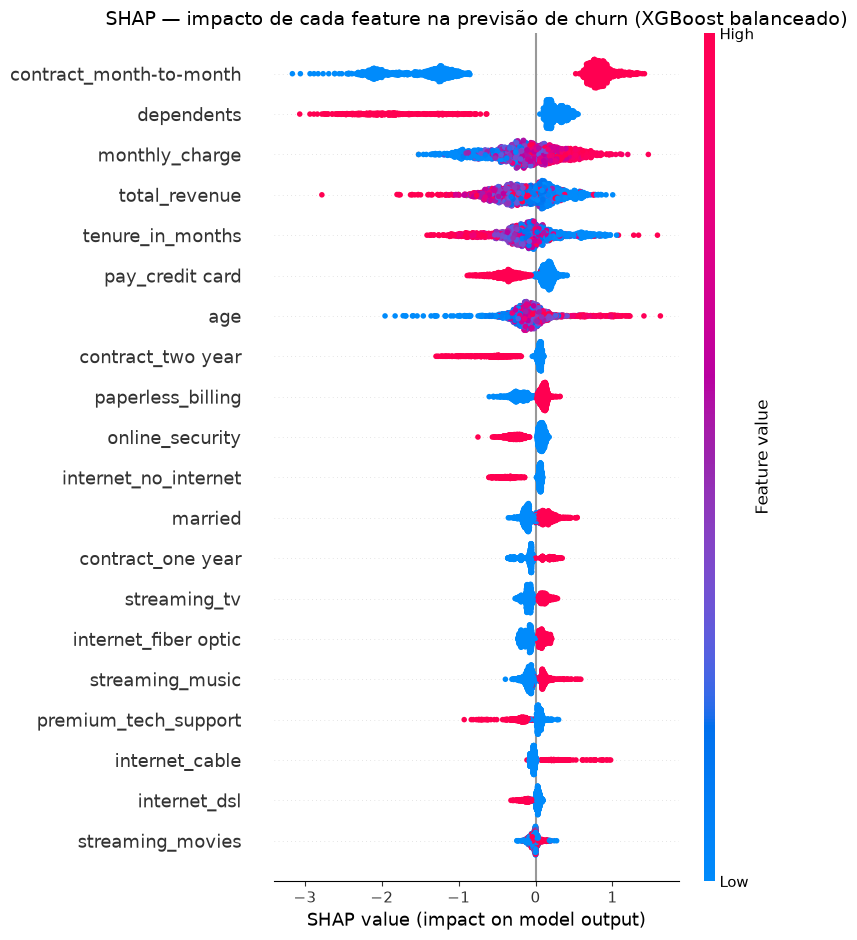

In [44]:
import shap
import matplotlib.pyplot as plt

# --- SHAP do XGBoost balanceado (scale_pos_weight) ---
# XGBoost lida com NaN nativamente (age tem NaN), então explica o X_test cru.
xgb_bal = xgb.XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.1,
    scale_pos_weight=scale_pos_weight, random_state=42,
)
xgb_bal.fit(X_train, y_train)

explainer = shap.TreeExplainer(xgb_bal)
expl = explainer(X_test)

# Extrai os SHAP values da classe "churn" (positiva), cobrindo os dois formatos
# que o shap pode retornar: (n, features, 2) ou (n, features).
if expl.values.ndim == 3:
    sv_churn = expl.values[:, :, 1]
else:
    sv_churn = expl.values

# --- 1) Importância média (mean |SHAP|) — barplot plotly ---
mean_abs = np.abs(sv_churn).mean(axis=0)
imp_shap_xgb = pd.DataFrame({'feature': X_sel.columns, 'shap': mean_abs}).sort_values('shap')

fig = px.bar(
    imp_shap_xgb, x='shap', y='feature', orientation='h',
    title='Importância média das features — SHAP (XGBoost balanceado)',
    labels={'shap': 'Mean |SHAP| (impacto médio na prob. de churn)', 'feature': ''},
    color_discrete_sequence=[YES_COLOR],
)
fig.update_layout(height=560, yaxis={'categoryorder': 'total ascending'})
fig.show()

# --- 2) Beeswarm: direção + magnitude de cada feature ---
shap.summary_plot(sv_churn, X_test, feature_names=X_sel.columns, show=False)
plt.title('SHAP — impacto de cada feature na previsão de churn (XGBoost balanceado)', fontsize=14)
plt.tight_layout()
plt.show()

### Conclusão — balanceamento não muda o ranking, mas muda o recall

Resultado da validação cruzada (métrica principal **PR-AUC**):

| Modelo | PR-AUC | Recall | F1 |
|---|---:|---:|---:|
| Gradient Boosting (com peso) | **0.7409** | **0.801** | 0.668 |
| Gradient Boosting (padrão) | 0.7398 | 0.603 | 0.653 |
| XGBoost (padrão) | 0.7331 | 0.617 | 0.659 |
| XGBoost (com peso) | 0.7320 | 0.775 | 0.670 |
| LightGBM (com peso) | 0.7269 | 0.765 | 0.664 |
| LightGBM (padrão) | 0.7234 | 0.616 | 0.659 |

- **PR-AUC (a ordem dos clientes) praticamente não muda** — dar mais peso aos churners muda onde o modelo "corta", não a ordem. As diferenças (~0.001–0.003) são ruído.
- **Recall sobe muito** em todos (+0.15 a +0.20): o modelo passa a pegar ~80% dos churners (vs ~60% antes), ao custo de mais alarmes falsos.
- Decisão de negócio: se **perder churner é caro** → balancear (mais recall); se **a capacidade de atendimento é limitada** → manter padrão (mais precisão). O vencedor por ranking continua o **Gradient Boosting**.

## Ajuste fino do modelo — Optuna (XGBoost & LightGBM)

Antes de fechar com o Gradient Boosting, tentamos melhorar XGBoost e LightGBM com **Optuna** (ferramenta que testa automaticamente muitas combinações de parâmetros e fica com a melhor). Regras mantidas:
- Validação cruzada (5 pedaços) **somente no treino** — o teste continua guardado até o fim.
- Métrica: **PR-AUC** — a mais honesta para churn desbalanceado.
- Sem parada antecipada (o número de árvores vem do próprio ajuste); sem vazamento.

In [45]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

# CV 5-fold SOMENTE no treino (teste travado)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective_xgb(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 200, step=25),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.3, 1.0, log=True),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.3, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 3, 10),
        'gamma': trial.suggest_float('gamma', 0.0, 5.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'random_state': 42,
        'n_jobs': 1,
    }
    model = xgb.XGBClassifier(**params)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='average_precision', n_jobs=1)
    return scores.mean()

study_xgb = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_xgb.optimize(objective_xgb, n_trials=50, show_progress_bar=True)

print(f'XGBoost — melhor PR-AUC (CV treino): {study_xgb.best_value:.4f}')
print('Melhores parâmetros:')
for k, v in study_xgb.best_params.items():
    print(f'  {k}: {v}')

Best trial: 25. Best value: 0.750029: 100%|██████████| 50/50 [00:29<00:00,  1.69it/s]

XGBoost — melhor PR-AUC (CV treino): 0.7500
Melhores parâmetros:
  n_estimators: 75
  max_depth: 3
  learning_rate: 0.09205159526335346
  subsample: 0.45295812362723964
  colsample_bytree: 0.4248449511637758
  min_child_weight: 6
  gamma: 0.22974951441953761
  reg_lambda: 0.4303510055198827
  reg_alpha: 0.014592276668810716


In [46]:
def objective_lgb(trial):
    # min_child_samples proporcional ao nº de exemplos de treino (fração), não um
    # valor absoluto fixo — assim não fica inválido se a base mudar de tamanho.
    # Ex.: 0.01 → 1% das linhas, 0.05 → 5%, 0.1 → 10%.
    n_train = len(X_train)
    min_child_fraction = trial.suggest_float('min_child_fraction', 0.005, 0.1, log=True)
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 200, step=25),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'num_leaves': trial.suggest_int('num_leaves', 2, 50, log=True),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_samples': max(1, int(n_train * min_child_fraction)),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'random_state': 42,
        'verbose': -1,
        'n_jobs': 1,
    }
    model = lgb.LGBMClassifier(**params)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='average_precision', n_jobs=1)
    return scores.mean()

study_lgb = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_lgb.optimize(objective_lgb, n_trials=50, show_progress_bar=True)

print(f'LightGBM — melhor PR-AUC (CV treino): {study_lgb.best_value:.4f}')
print('Melhores parâmetros:')
for k, v in study_lgb.best_params.items():
    print(f'  {k}: {v}')

Best trial: 16. Best value: 0.747384: 100%|██████████| 50/50 [00:33<00:00,  1.51it/s]

LightGBM — melhor PR-AUC (CV treino): 0.7474
Melhores parâmetros:
  min_child_fraction: 0.017164349090347142
  n_estimators: 175
  max_depth: 7
  num_leaves: 10
  learning_rate: 0.027456589071203994
  subsample: 0.6780994971072903
  colsample_bytree: 0.600936890863098
  reg_lambda: 0.5942693358620219
  reg_alpha: 0.07125296155804164


In [47]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# --- Disputa final no holdout (teste travado, usado uma única vez) ---
# Retreina os modelos tunados + o Gradient Boosting (default) no treino completo
# e compara PR-AUC no teste, que ficou intacto durante todo o tuning.
best_xgb = xgb.XGBClassifier(**study_xgb.best_params, random_state=42)
best_xgb.fit(X_train, y_train)

# CORREÇÃO: study_lgb.best_params traz `min_child_fraction`, que NÃO é parâmetro
# do LGBMClassifier (ele aceita e ignora silenciosamente). Reconverte para o
# `min_child_samples` real, em nº de exemplos do treino.
lgb_params = dict(study_lgb.best_params)
min_child_fraction = lgb_params.pop('min_child_fraction', None)
if min_child_fraction is not None:
    lgb_params['min_child_samples'] = max(1, int(len(X_train) * min_child_fraction))

best_lgb = lgb.LGBMClassifier(**lgb_params, random_state=42, verbose=-1)
best_lgb.fit(X_train, y_train)

# GradientBoosting (sklearn) NÃO aceita NaN nativamente -> imputação da mediana
# dentro de um pipeline (mesma estratégia da comparação de 8 modelos).
gb_default = Pipeline([
    ('imp', SimpleImputer(strategy='median')),
    ('clf', GradientBoostingClassifier(random_state=42)),
])
gb_default.fit(X_train, y_train)

res_final = {}
for nome, mdl in {
    'XGBoost tunado': best_xgb,
    'LightGBM tunado': best_lgb,
    'Gradient Boosting (default)': gb_default,
}.items():
    p = mdl.predict_proba(X_test)[:, 1]
    res_final[nome] = {
        'PR-AUC': average_precision_score(y_test, p),
        'ROC-AUC': roc_auc_score(y_test, p),
    }

pd.DataFrame(res_final).T.round(4).sort_values('PR-AUC', ascending=False)

,PR-AUC,ROC-AUC
Gradient Boosting (default),0.7567,0.8951
XGBoost tunado,0.7497,0.8910
LightGBM tunado,0.7467,0.8937


In [48]:
# --- Gráfico de métricas: comparação visual dos 3 finalistas (holdout) ---
modelos_finais = {
    'Gradient Boosting': gb_default,
    'XGBoost': best_xgb,
    'LightGBM': best_lgb,
}
cores_modelos = {
    'Gradient Boosting': CHURN_COLOR,
    'XGBoost': YES_COLOR,
    'LightGBM': NO_CHURN_COLOR,
}

metrica = {}
for nome, mdl in modelos_finais.items():
    p = mdl.predict_proba(X_test)[:, 1]
    y_hat = (p >= 0.5).astype(int)
    metrica[nome] = {
        'PR-AUC': average_precision_score(y_test, p),
        'ROC-AUC': roc_auc_score(y_test, p),
        'Acurácia': accuracy_score(y_test, y_hat),
        'Precisão': precision_score(y_test, y_hat),
        'Recall': recall_score(y_test, y_hat),
        'F1': f1_score(y_test, y_hat),
    }

df_metrica = pd.DataFrame(metrica).T.round(3)

fig = go.Figure()
for nome in df_metrica.index:
    fig.add_trace(go.Bar(
        x=df_metrica.columns, y=df_metrica.loc[nome],
        name=nome, marker_color=cores_modelos[nome],
        text=df_metrica.loc[nome].astype(str),
        textposition='outside',
    ))

fig.update_layout(
    title=dict(text='Métricas no holdout — comparação dos 3 finalistas', x=0, font=dict(size=18)),
    barmode='group',
    height=440,
    plot_bgcolor='white',
    yaxis=dict(range=[0, 1.05], title='Valor da métrica'),
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1),
    margin=dict(l=10, r=10, t=70, b=10),
)
fig.show()

df_metrica

,PR-AUC,ROC-AUC,Acurácia,Precisão,Recall,F1
Gradient Boosting,0.757,0.895,0.839,0.740,0.604,0.665
XGBoost,0.750,0.891,0.840,0.739,0.612,0.670
LightGBM,0.747,0.894,0.840,0.740,0.615,0.671


## Guia de interpretação das métricas

Para apresentar, o que cada métrica significa em linguagem de negócio:

- **PR-AUC**: *"o quão bom é o ranking dos churners"* — **métrica principal**. Mede se o modelo coloca os prováveis churners no topo da lista, independentemente do ponto de corte escolhido. Ideal para churn desbalanceado.
- **Recall**: *"quantos churners eu peguei"* — alta quando **perder cliente é caro** (melhor acionar quem vai sair, mesmo errando alguns).
- **Precision**: *"quantos da minha fila realmente iam sair"* — alta quando a **capacidade de atendimento é limitada** (não posso acionar muita gente à toa).
- **F1**: *"equilíbrio entre os dois"* — útil para comparar modelos, mas não revela a troca (por isso olhamos recall e precision separados).

### A troca central (para discutir na apresentação)
Recall e precision puxam para lados opostos: aumentar o recall (pegar mais churners) reduz a precision (mais alarmes falsos). O ponto de corte ideal depende do **custo do churn vs. custo da ação de retenção**.

In [49]:
import plotly.graph_objects as go

# --- Churn por decil: comparação entre os 3 modelos ---
# Para cada modelo, ordena as probabilidades do holdout em 10 decis e mede a
# taxa REAL de churn em cada decil. Quanto mais "empinada" a curva, melhor o
# modelo separa churners de não-churners (e mais útil para priorizar ação).

modelos = {
    'Gradient Boosting': gb_default,
    'XGBoost': best_xgb,
    'LightGBM': best_lgb,
}

cores = {
    'Gradient Boosting': CHURN_COLOR,
    'XGBoost': YES_COLOR,
    'LightGBM': NO_CHURN_COLOR,
}

tabela = {}
fig = go.Figure()

for nome, mdl in modelos.items():
    proba = mdl.predict_proba(X_test)[:, 1]
    df = pd.DataFrame({'proba': proba, 'real': y_test})
    df['decil'] = pd.qcut(df['proba'], q=10, duplicates='drop', labels=False) + 1
    taxa = df.groupby('decil')['real'].mean() * 100
    tabela[nome] = taxa
    fig.add_trace(go.Scatter(
        x=taxa.index, y=taxa.values,
        mode='lines+markers', name=nome,
        line=dict(color=cores[nome], width=2),
        marker=dict(color=cores[nome], size=7),
        hovertemplate=f'{nome}<br>Decil %{{x}}: %{{y:.1f}}%<extra>% churn real</extra>',
    ))

fig.update_layout(
    title=dict(text='Churn real por decil — comparação entre modelos', x=0, font=dict(size=18)),
    xaxis_title='Decil de probabilidade predita (1 = menor, 10 = maior)',
    yaxis_title='% de churn real',
    height=440,
    plot_bgcolor='white',
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1),
    margin=dict(l=10, r=10, t=70, b=10),
)
fig.update_xaxes(tickvals=list(range(1, 11)))
fig.show()

# tabela lado a lado (linha = decil, coluna = modelo)
pd.DataFrame(tabela).round(1)

,Gradient Boosting,XGBoost,LightGBM
decil,,,
1,1.1,1.1,0.0
2,0.6,0.6,1.7
3,0.6,1.7,0.6
4,5.1,5.1,5.1
5,10.8,11.9,9.1
6,20.5,19.3,23.3
7,30.1,27.8,29.0
8,43.8,47.2,45.5
9,67.6,67.6,68.2


## Explicabilidade — SHAP (Gradient Boosting)

O vencedor foi o **Gradient Boosting**. Como é um conjunto de árvores de decisão, o SHAP funciona direto — ele **decompõe cada previsão** em "quanto cada fator empurrou para sair ou ficar".

O que vamos ver:
1. **Importância média**: quanto cada fator empurra a chance de churn, em média.
2. **Mapa de pontos (beeswarm)**: cada ponto é um cliente; a cor indica o valor do fator (vermelho alto, azul baixo) e a posição o impacto (direita = aumenta churn, esquerda = reduz).
3. **Gráficos de dependência** dos 3 mais importantes: como o impacto muda conforme o valor do fator.

/var/folders/jc/rjmj1sg905770lykj5tgg1f80000gp/T/ipykernel_46557/2619310473.py:35: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_churn, X_test_imp, feature_names=X_sel.columns, show=False)


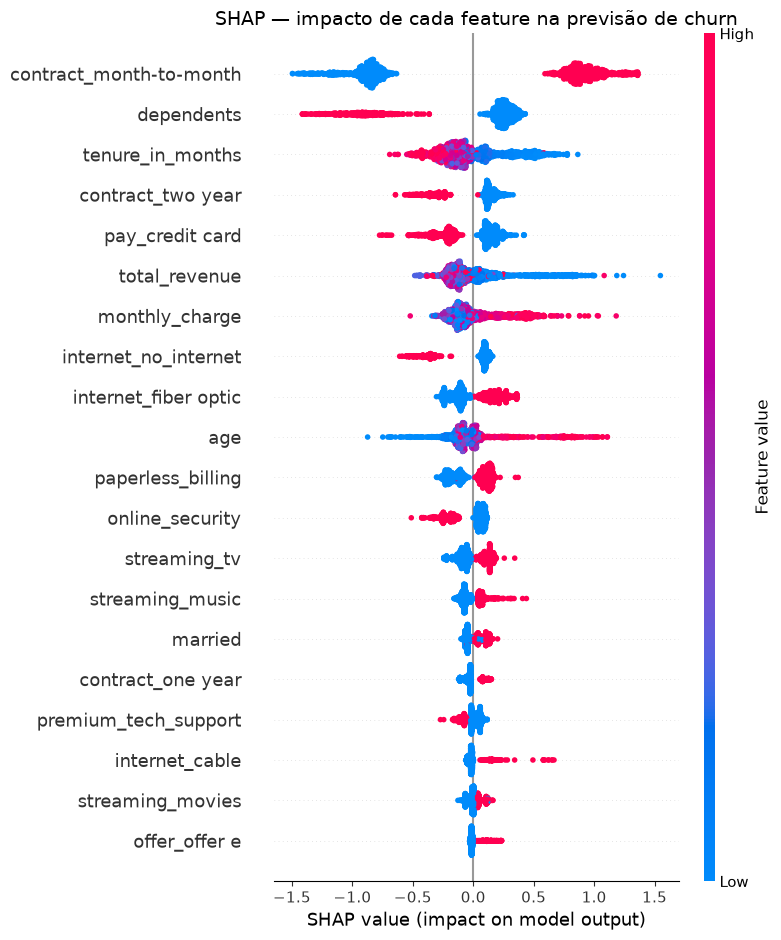

In [50]:
import shap
import matplotlib.pyplot as plt

# --- SHAP do modelo vencedor: Gradient Boosting ---
# O modelo está num pipeline (imputer + GradientBoostingClassifier). Extraímos o
# estimador treinado e imputamos o X_test (age tem NaN) antes de explicar.
gb = gb_default.named_steps['clf']
imp = gb_default.named_steps['imp']
X_test_imp = pd.DataFrame(imp.transform(X_test), columns=X_sel.columns, index=X_test.index)

explainer = shap.TreeExplainer(gb)
expl = explainer(X_test_imp)

# Extrai os SHAP values da classe "churn" (positiva), cobrindo os dois formatos
# que o shap pode retornar: (n, features, 2) ou (n, features).
if expl.values.ndim == 3:
    sv_churn = expl.values[:, :, 1]
else:
    sv_churn = expl.values

# --- 1) Importância média (mean |SHAP|) — barplot plotly ---
mean_abs = np.abs(sv_churn).mean(axis=0)
imp_shap = pd.DataFrame({'feature': X_sel.columns, 'shap': mean_abs}).sort_values('shap')

fig = px.bar(
    imp_shap, x='shap', y='feature', orientation='h',
    title='Importância média das features — SHAP (Gradient Boosting)',
    labels={'shap': 'Mean |SHAP| (impacto médio na prob. de churn)', 'feature': ''},
    color_discrete_sequence=[CHURN_COLOR],
)
fig.update_layout(height=560, yaxis={'categoryorder': 'total ascending'})
fig.show()

# --- 2) Beeswarm: direção + magnitude de cada feature ---
shap.summary_plot(sv_churn, X_test_imp, feature_names=X_sel.columns, show=False)
plt.title('SHAP — impacto de cada feature na previsão de churn', fontsize=14)
plt.tight_layout()
plt.show()

## Conclusões da explicabilidade (SHAP — Gradient Boosting)

Interpretação de negócio dos fatores que mais impactam a previsão de churn:

- **Contrato mês a mês**: **aumenta** a chance de churn. Consistente com a EDA (mês a mês churn ~46% vs ~2,5% do bianual).
- **Sem dependentes**: clientes sem dependentes têm maior chance de churn.
- **Pouco tempo de casa**: quanto **menor** o tempo de fidelidade, **maior** a chance de churn (clientes novos são os mais propensos a sair).
- **Contrato de dois anos**: **reduz** a chance de churn (ajuda na previsão de **não churn**).
- **Não pagar no cartão de crédito**: clientes que pagam por débito em conta ou boleto têm maior chance de churn.

### Resumo do perfil de maior risco
Cliente com **contrato mês a mês**, **sem dependentes**, **pouco tempo de casa** e que **não paga no cartão de crédito** é o alvo prioritário de retenção.

# Respondendo o case — as quatro entregas

Este notebook fecha as quatro entregas do case técnico. A primeira (modelo) está **implementada** nas células acima; as três seguintes são **propostas estruturadas** (sem implementação, como pedido).

## 1. Modelo de classificação — churn vs não churn

**Resultado final: Gradient Boosting** — um algoritmo que combina centenas de árvores de decisão simples, onde cada árvore tenta corrigir os erros da anterior. Foi o que melhor ordenou os clientes do mais ao menos propenso a sair (PR-AUC **0,757** · ROC-AUC **0,895**, medidos em clientes que o modelo nunca tinha visto). Abaixo, cada ponto do enunciado respondido.

### 1.1 Análise exploratória (EDA)
- Taxa de churn **26,5%**; 1.869 churners em 7.043 clientes.
- **Motivos**: concorrência domina (~45% dos churners); depois atendimento/insatisfação (~33%), preço e outros.
- Taxas de churn por tipo de variável: **sim/não** (serviços, demográficas), **categorias** (contrato, internet, pagamento, oferta), **números** (tempo de casa, faixas), **geografia** (cidade) e **o quanto as variáveis andam juntas** (correlação) — células de EDA no início do notebook.
- Diferenças expressivas: contrato **18,3×**, dependentes **5×**, oferta E **7,9×**.

### 1.2 Testes estatísticos de qualidade das features
- **eBoruta** — técnica que compara cada variável com uma versão "embaralhada" dela (ruído puro). Se a variável não prevê melhor que o ruído, ela é descartada. Com a semente fixa (42), o resultado ficou estável: **22 aceitas + 3 indecisas = 25 features**.
- **Correlação** — mede o quanto duas variáveis andam juntas. Detectou que `total_charges` e `total_revenue` andam quase juntas (+0,92) — medem quase a mesma coisa, então uma foi descartada.
- **Comparação de taxas por grupo** — efeito descritivo (18,3×, 5×, 7,9×) para priorizar as variáveis que mais explicam.

### 1.3 Limpeza, pré-processamento e "coisas estranhas"
- **Caixa das letras**: colunas e valores vinham com maiúsculas/minúsculas misturadas (`Stayed`/`STAYED`/`stayed`, `yes`/`Yes`/`YES`) → padronizado para minúsculas.
- **Sim/não em texto**: `'yes'/'no'` viraram verdadeiro/falso comparando o texto em minúsculas com `'yes'` (evita o erro de converter qualquer texto não vazio em "verdadeiro").
- **Valores absurdos**: `age` chegava a **9.905 anos** (e várias colunas numéricas tinham valores na casa dos 9 mil). Decisão: idade acima de 100 anos vira "ausente" — não apagamos a linha do cliente.
- **Campos vazios**: `internet_type` `'none'` virou "ausente" (não tem internet); `offer` vazio virou `'none'` (não ter oferta é uma categoria válida). Sentidos opostos, ambos corretos.
- **Variáveis criadas**: `has_internet`, `num_services`, `customer_type`; cada categoria das variáveis textuais virou uma coluna de sim/não (ex.: contrato "mês a mês" vira uma coluna própria).
- **Coisas estranhas encontradas**: valores ~9 mil nas colunas numéricas; `quarter` só tem Q3 (não varia — inútil); `country`/`state` têm um único valor; `number_of_dependents` não tem inconsistência com a versão sim/não (usamos só a sim/não).

**Colunas excluídas (e por quê):**

| Coluna | Motivo |
|---|---|
| `churn_score`, `customer_status`, `churn_category`, `churn_reason` | já contêm a resposta (só existem para quem saiu) — usar seria trapaça |
| `total_charges` | mede quase a mesma coisa que `total_revenue` (correlação +0,92) |
| `quarter` | só Q3, não varia |
| `number_of_dependents` | repetida — a versão sim/não `dependents` já cobre |
| `country`, `state` | têm um único valor |
| `streaming_gb_cols` | o nível 0–3 não diferencia churn (só o "tem ou não" importa) |
| `customer_id`, `zip_code`, `latitude`, `longitude` | identificadores / localização sem leitura útil |
| `population`, `number_of_referrals` | decisão de negócio — não acionável / já coberto pelo sim/não |

### 1.4 Escolha do algoritmo
- Comparei **8 algoritmos** (regressão logística, vizinhos próximos, florestas, boosting e afins), medindo cada um por validação cruzada (5 medições) e ranqueando por **PR-AUC**.
- **Gradient Boosting venceu** (PR-AUC 0,740); os modelos baseados em árvores superaram os lineares.
- O ajuste fino com Optuna (item 1.7) **não superou** a configuração padrão — mantivemos o padrão, mais simples e robusto.

### 1.5 Motivo da métrica de avaliação
- **PR-AUC** como métrica principal: mede **o quão bem o modelo ordena** os clientes — quem tem mais chance de sair fica no topo da lista. É a certa aqui porque churn é minoria (26,5%) e porque **não depende de escolher um ponto de corte**.
- **ROC-AUC** pode parecer otimista demais em classes desbalanceadas; acurácia engana (um modelo que diz "ninguém sai" já acertaria ~73%).
- **Recall/precision/F1** entram na **decisão de negócio**: perder cliente é caro → priorizar recall (pegar mais churners); capacidade de atendimento é limitada → priorizar precision (acionar menos gente, com mais certeza).

### 1.6 Treinamento e teste
- **Divisão 75/25 mantendo a proporção de churn** (semente 42) — o teste fica **guardado** e só é usado na avaliação final.
- **Validação cruzada (5 pedaços) só no treino** — o teste nunca participa de seleção ou ajuste (não vaza informação).
- Preenchimento da idade ausente feito dentro de cada pedaço (sem vazamento).

### 1.7 Ajuste do modelo
- **Optuna** — ferramenta que testa automaticamente milhares de combinações de parâmetros e fica com a melhor. Usada para tentar superar o padrão, medindo sempre por PR-AUC na validação cruzada.
- XGBoost ajustado: PR-AUC **0,750** · LightGBM ajustado: **0,747** — **não superaram** o GB padrão (0,757).
- **Balanceamento de classes** (testado): dar mais peso aos churners (que são minoria). O ranking não mudou, mas o **recall subiu para ~0,80** — o modelo passa a "pegar" mais churners, ao custo de mais alarmes falsos.

### 1.8 Principais fatores de churn (explicabilidade)
Via **SHAP** — técnica que mostra, para cada cliente, quanto cada fator empurrou a previsão para "sai" ou "fica":
- **Contrato mês a mês** — o maior fator; aumenta o churn.
- **Sem dependentes** — aumenta o churn.
- **Pouco tempo de casa** — aumenta o churn (cliente novo).
- **Não pagar no cartão** — aumenta o churn.
- **Contrato de 2 anos** — reduz o churn (protege).

**Perfil de maior risco**: contrato mês a mês, sem dependentes, pouco tempo de casa e que não paga no cartão.

## 2. Features adicionais propostas (para previsão futura)

Sem implementação — ideias organizadas por fonte de sinal. Tema central: o modelo atual usa a "foto" de um trimestre (dados **do mesmo momento** do churn). As features de maior valor são as **temporais**, que transformam "detectar tarde" em "antecipar".

### 2.1 Quais features podem ser utilizadas

**Temporais / históricas (maior valor)**
- Tendência de uso nos últimos 30/60/90 dias — a queda de consumo aparece antes do cancelamento.
- Variação mês a mês (dados, ligações, receita) — não só o valor atual, mas **se está subindo ou caindo**.
- Histórico de tempo de casa, mês a mês, em vez do valor único de um trimestre.

**Comportamentais / engajamento**
- Logins no app/portal, nº de chamadas e tickets, tempo de resolução — cliente que reclama muito já está em risco.
- Padrão de interação digital vs. analógico.

**Financeiras**
- Atrasos de pagamento, nº de faturas em atraso, negociações.
- Mudanças de plano (subir/descer) e mudanças de preço.
- Tentativas prévias de cancelamento, mesmo não concluídas.

**Concorrência / mercado**
- Ofertas e preços dos concorrentes — o principal motivo de churn é "competidor" (45%).
- Quantidade de concorrentes na região do cliente.

**Satisfação / relacional**
- NPS/CSAT (notas de satisfação) e respostas a pesquisas.
- Sinais de atrito parcial (cancelou um serviço, manteve outro).

### 2.2 Impactos positivos e negativos esperados

**Positivos**
- **Antecipar em vez de detectar**: capturar o declínio antes do cancelamento.
- **Melhor separação**: features temporais e comportamentais devem melhorar o ranking (PR-AUC) e, sobretudo, o recall (pegar mais churners a tempo).
- **Abre caminho para modelos de "quando" e "onde"**: com histórico, dá para modelar quando agir e em quem a ação funciona.
- **Ação mais certeira**: features de concorrência e satisfação ligam o modelo à causa (não só à correlação).

**Negativos / riscos**
- **Custo de coleta e integração**: exige cruzar CRM, cobrança, app e call center.
- **Modelo fica mais pesado** e a base de dados cresce bastante, principalmente se quisermos prever todos os clientes da empresa.

### 2.3 Dificuldade para construir essas features

- **Sem histórico**: a base atual tem um único trimestre (Q3) — não há meses anteriores para derivar tendências; seria preciso coletá-los.
- **Sistemas separados**: features comportamentais/financeiras estão espalhadas (app, CRM, cobrança) e precisam de um fluxo de dados consistente.
- **Qualidade das datas**: registros precisam de timestamps confiáveis e alinhados por cliente ao longo do tempo.
- **Dados de terceiros**: monitorar concorrência exige dados externos (custoso e difícil de automatizar).
- **Viés de resposta**: NPS/CSAT só existem para quem responde — não cobre a base toda.
- **Privacidade**: dados comportamentais podem ter restrições (LGPD/GDPR).

## 3. Próximos passos para melhoria do modelo

### Dados e representatividade
- **Validar se a base representa a realidade** — churn tem sazonalidade e a base atual só tem Q3; coletar vários trimestres.
- **Adicionar histórico** (painel) para modelar **quando** o cliente sai, não só **se** — é o que permitiria agir a tempo.

### Modelagem
- **Análise de sobrevivência** (estimar em quanto tempo o cliente sai) — para descobrir a janela de tempo em que ainda dá para agir.
- **Modelagem de uplift** (medir o efeito da ação em cada cliente) — para decidir **onde** agir, não apenas quem está em risco.
- **Calibração de probabilidade** — ajustar o número de saída para que "70% de chance" signifique mesmo 70%, se for alimentar uma decisão de negócio.
- **Combinar os melhores modelos** (GB + XGB + LightGBM) em um só.

### Decisão / operacional
- **Escolher o ponto de corte pelo custo-benefício** (custo do churn vs. custo da ação de retenção).
- **Validar no tempo** (treinar no passado e testar no futuro), em vez de um único corte fixo.
- **Monitorar mudanças** no comportamento dos dados e retreinar periodicamente em produção.
- Se perder churner for caro: **adotar o modelo balanceado** (recall ~0,80, já testado neste notebook).

## 4. Teste para validar a eficácia das ações de prevenção

O time comercial já tem ações definidas. O objetivo do teste **não é provar que o modelo acerta churn** (isso já medimos) — é medir o **efeito real da ação**: quanto ela reduz o churn, e em **quais faixas de risco**.

### 4.1 Planejamento
- **Hipótese**: "a ação A reduz o churn em X pontos percentuais nos clientes-alvo".
- **População**: clientes ordenados pelo modelo (não a base inteira).
- **Sorteio por faixa**: agrupar em 3–4 faixas de risco (não 10) e sortear tratamento/controle **dentro de cada faixa**.
- **Grupos**: controle (não recebe a ação) vs. tratamento (recebe), sem deixar um grupo "vazar" para o outro.
- **Métrica principal**: taxa de churn no período. **Métrica de decisão**: o efeito da ação = churn do controle menos churn do tratamento.
- **Tamanho da amostra**: calcular o menor efeito que o teste consegue detectar com segurança, para ter poder estatístico em cada faixa.
- **Duração e pré-registro**: janela de observação suficiente (ex. 60–90 dias) e análise definida antes de rodar.

### 4.2 Execução
- Sorteio limpo e **garantir que só quem foi sorteado recebe a ação**.
- **Evitar contaminação** entre grupos (a ação não pode chegar ao controle).

### 4.3 Análise
- **Efeito por faixa de risco** — onde a ação salva? O topo pode ser "caso perdido" (sai de qualquer jeito) e o meio, onde a ação tem efeito real.
- **Testar se a diferença de churn entre os grupos é significativa**, em cada faixa.
- **Quatro perfis de cliente**:
  - *Persuadíveis* (sairiam sem a ação, ficam com ela) → **alvo da ação**.
  - *Caso perdido* (saem de qualquer jeito) → não gastar.
  - *Fiéis* (não saem) → ignorar.
  - *Reativos* (saem **só porque** receberam a ação) → **evitar**.
- **Custo-benefício**: efeito da ação × valor do cliente vs. custo da ação.

### 4.4 Decisão
- **Manter, escalar ou abandonar** a ação com base no efeito por faixa.
- **Direcionar a ação às faixas de maior efeito** — que podem não ser o topo do modelo.
- **Treinar um modelo de efeito** com os dados do experimento: decidir por `efeito × valor`, não por `probabilidade de sair × valor`.

**A sacada temporal**: se o modelo acerta o churn porque o sinal **já é o churn em curso**, a ação chega tarde. Com o histórico do cliente, modelamos **a probabilidade de sair daqui a N meses dado o estado atual** e descobrimos a **janela de ação** — o momento em que ainda dá para agir antes do ponto sem volta.